In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import sys
sys.path.append('/media/dll-1/SSD 4TB/code/LEEDNet/')  # Replace with real path
from EEGDataLoader import EEGDataset
from models.LEEDNetModel import LEEDNetModel
import config
from train_eval import eval, train

model_saving_name = "/media/dll-1/SSD 4TB/EEG Datasets/experiment/nouman_conv_2/model/weights/conv_tt_0_original.pt"

epochs = 50
batch_size = 64
hidden_size = 20
output_size = 3  # Binary classification
number_of_eeg_channels = 1
eval_batch = 1
threshold = 0.495
active_branches = [0]

/home/anaconda/anaconda3/envs/braindecode/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
train_dataset = EEGDataset(config.train_data_csv, number_of_eeg_channels=number_of_eeg_channels)
val_dataset = EEGDataset(config.val_data_csv, number_of_eeg_channels=number_of_eeg_channels)
test_dataset = EEGDataset(config.test_data_csv, number_of_eeg_channels=number_of_eeg_channels)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)#, collate_fn=collate)
val_loader = DataLoader(val_dataset, batch_size=eval_batch, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=eval_batch, shuffle=False)

In [ ]:
input = train_dataset.__getitem__(0)
input_x1 = input[1].shape
input_x2 = input[2].shape
input_x3 = input[3].shape
criterion = nn.CrossEntropyLoss()

loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

print(input_x1,input_x2,input_x3)
input_channels_list = [input_x1[1], input_x2[1], input_x3[1]]

model = LEEDNetModel(input_channels_list=input_channels_list, output_size=3)

main_output, aux_outputs = model([input[1], input[2], input[3]], active_branch_indices=active_branches)
print("Output shape:", main_output.shape) 

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001,betas=(0.9, 0.98), eps=1e-9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:57: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at ../aten/src/ATen/native/Copy.cpp:305.)
  coefficients_cmor = torch.tensor(coefficients_cmor, dtype=torch.float32)
/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


torch.Size([1, 1, 400]) torch.Size([1, 33, 14]) torch.Size([1, 30, 400])
Output shape: torch.Size([1, 3])


ConvParallelEEG1DModel(
  (branches): ModuleList(
    (0): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(in_features=32, out_features=3, bias=True)
    )
    (1): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(33, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(

In [4]:
model_state_dict = torch.load(model_saving_name)
# Load the state_dict into the model
model.load_state_dict(model_state_dict)


/tmp/ipykernel_90911/2470549735.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_state_dict = torch.load(model_saving_name)


<All keys matched successfully>


Running model on a subset of test data to collect features for t-SNE...


  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


Collected features from 74774 samples.
(74774, 32)
(74774,)
Running t-SNE on 74774 samples with 74774 labels...
t-SNE calculation complete.


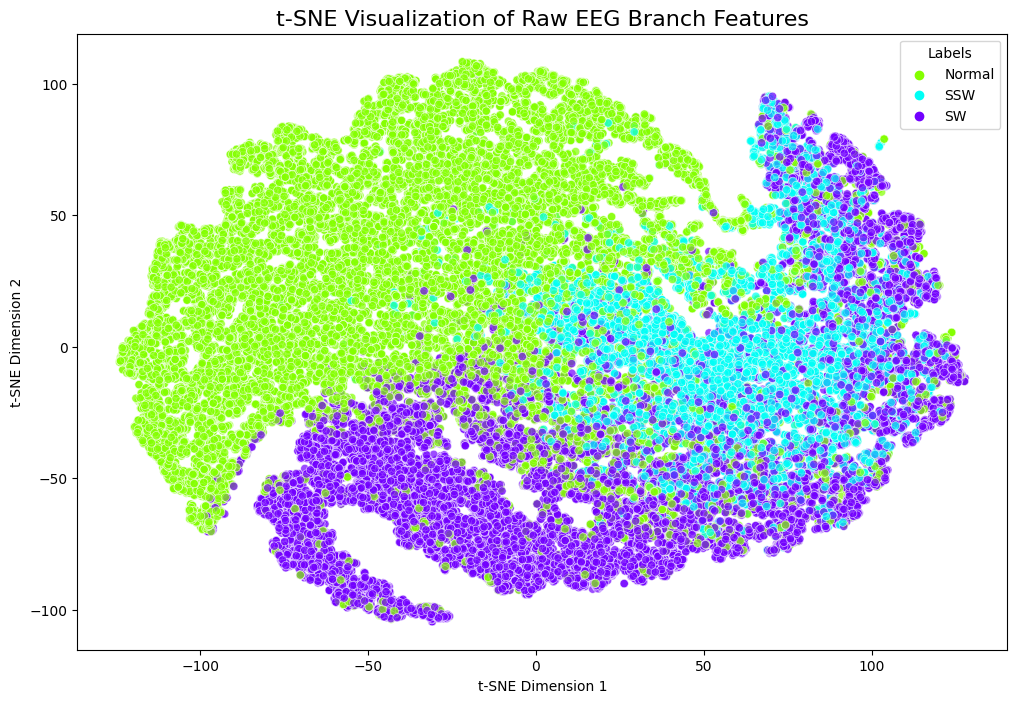

In [7]:
# ====================================================================
# BLOCK 1: t-SNE VISUALIZATION OF RAW EEG BRANCH FEATURES (Corrected)
# ====================================================================
from sklearn.manifold import TSNE
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import collections
from tqdm import tqdm

# --- Step 1: Set up the hook to capture the features ---
features = []

def get_features_hook(module, input, output):
    features.append(output[0].cpu().detach().numpy())

# --- Step 2: Run a subset of data through the model to collect features ---
try:
    print("\nRunning model on a subset of test data to collect features for t-SNE...")
    
    hook_handle = model.branches[0].register_forward_hook(get_features_hook)
    true_labels = []
    num_samples_for_tsne = 2000
    samples_collected = 0

    model.eval()
    with torch.no_grad():
        for _, eeg_data, fft_data, wavelet_data, labels in tqdm(test_loader, desc="Collecting Features"):
            # if samples_collected >= num_samples_for_tsne:
                # break
            
            eeg_data_squeezed = eeg_data.squeeze(1).to(device)
            fft_data_squeezed = fft_data.squeeze(1).to(device)
            wavelet_data_squeezed = wavelet_data.squeeze(1).to(device)

            model_inputs = [eeg_data_squeezed, fft_data_squeezed, wavelet_data_squeezed]
            
            _ = model(model_inputs, active_branch_indices=active_branches)
            
            true_labels.extend(labels.cpu().numpy())
            samples_collected += eeg_data.size(0)

    hook_handle.remove()
    print(f"Collected features from {samples_collected} samples.")

    # --- Step 3: Format data and run t-SNE ---
    features_np = np.concatenate(features, axis=0)
    # true_labels_np = np.array(true_labels)[:features_np.shape[0]]
    true_labels_np = np.array(true_labels)
    print(features_np.shape)
    print(true_labels_np.shape)
    
    print(f"Running t-SNE on {features_np.shape[0]} samples with {true_labels_np.shape[0]} labels...")
    tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, learning_rate='auto', init='pca')
    tsne_results = tsne.fit_transform(features_np)
    print("t-SNE calculation complete.")

    label_map = {
        0: 'Normal',
        1: 'SSW',  # Sharp and Spike Wave
        2: 'SW'    # Slow Wave
    }
    

    true_labels_mapped = [label_map[label] for label in true_labels_np]

    tsne_df = pd.DataFrame({
        'tsne-2d-one': tsne_results[:,0],
        'tsne-2d-two': tsne_results[:,1],
        'Labels': true_labels_mapped 
    })

    plt.figure(figsize=(12, 8))
    
    sns.scatterplot(
        x="tsne-2d-one", y="tsne-2d-two",
        hue="Labels", 
        hue_order=['Normal', 'SSW', 'SW'], 
        palette=sns.color_palette("hsv", n_colors=len(label_map)), 
        data=tsne_df,
        legend="full",
        alpha=0.7
    )
    plt.title('t-SNE Visualization of Raw EEG Branch Features', fontsize=16)
    plt.xlabel('t-SNE Dimension 1')
    plt.ylabel('t-SNE Dimension 2')
    plt.show()

except NameError as e:
     print(f"\nSkipping t-SNE analysis because a required variable was not found: {e}")
except Exception as e:
    print(f"\nAn error occurred during t-SNE analysis: {e}")

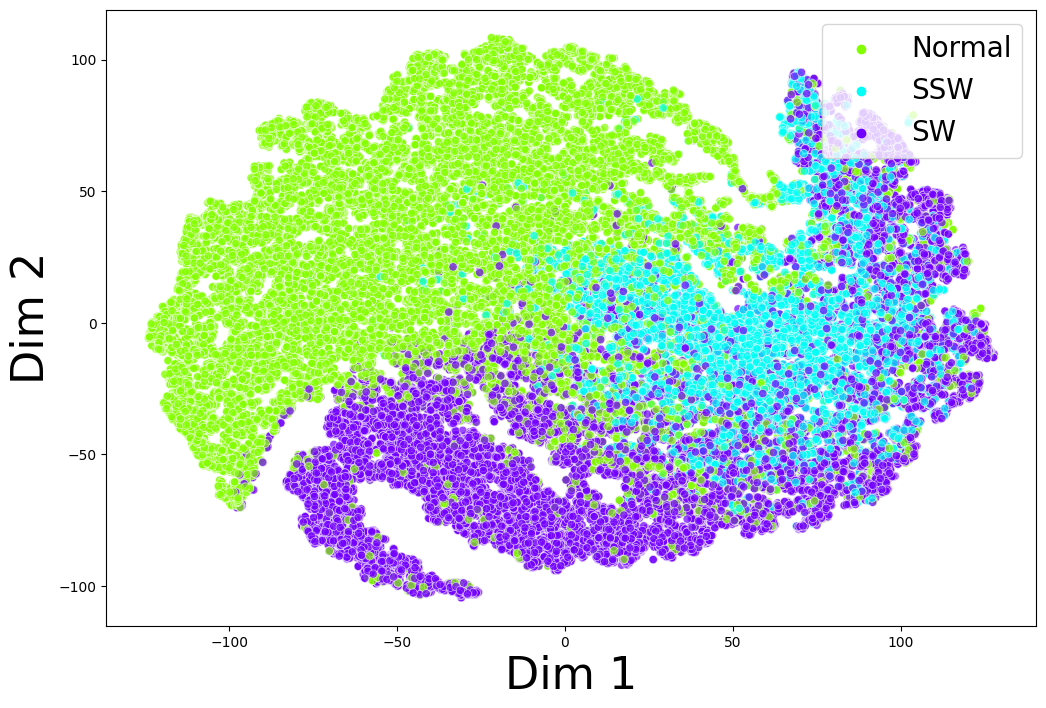

In [27]:
label_map = {
    0: 'Normal',
    1: 'SSW',  # Sharp and Spike Wave
    2: 'SW'    # Slow Wave
}


true_labels_mapped = [label_map[label] for label in true_labels_np]

tsne_df = pd.DataFrame({
    'tsne-2d-one': tsne_results[:,0],
    'tsne-2d-two': tsne_results[:,1],
    'Labels': true_labels_mapped 
})

plt.figure(figsize=(12, 8))

sns.scatterplot(
    x="tsne-2d-one", y="tsne-2d-two",
    hue="Labels", 
    hue_order=['Normal', 'SSW', 'SW'], 
    palette=sns.color_palette("hsv", n_colors=len(label_map)), 
    data=tsne_df,
    legend="full",
    alpha=0.7
)

plt.xlabel('Dim 1', fontsize=32)
plt.ylabel('Dim 2', fontsize=32)

plt.legend(fontsize=20, title=None, loc='upper right')

plt.show()


--- Starting Captum Analysis for 4 Samples ---

--- Analyzing Sample #1 (Index: 0) ---
True Label: 0 | Model Prediction: 1


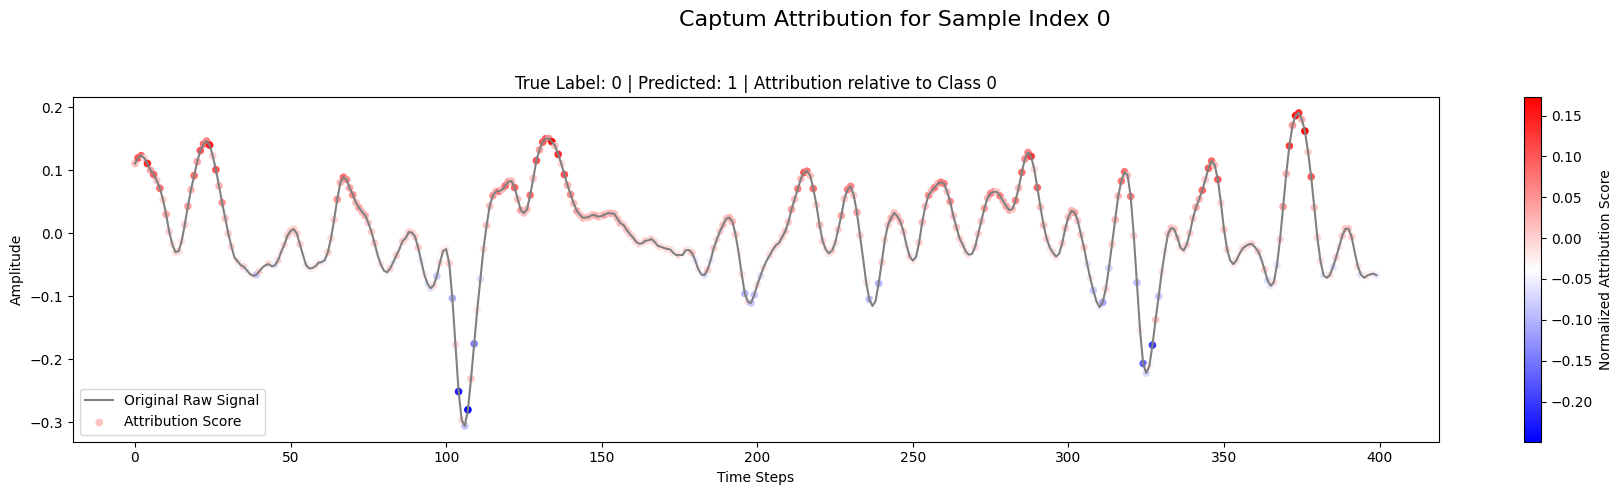


--- Analyzing Sample #2 (Index: 10) ---
True Label: 1 | Model Prediction: 1


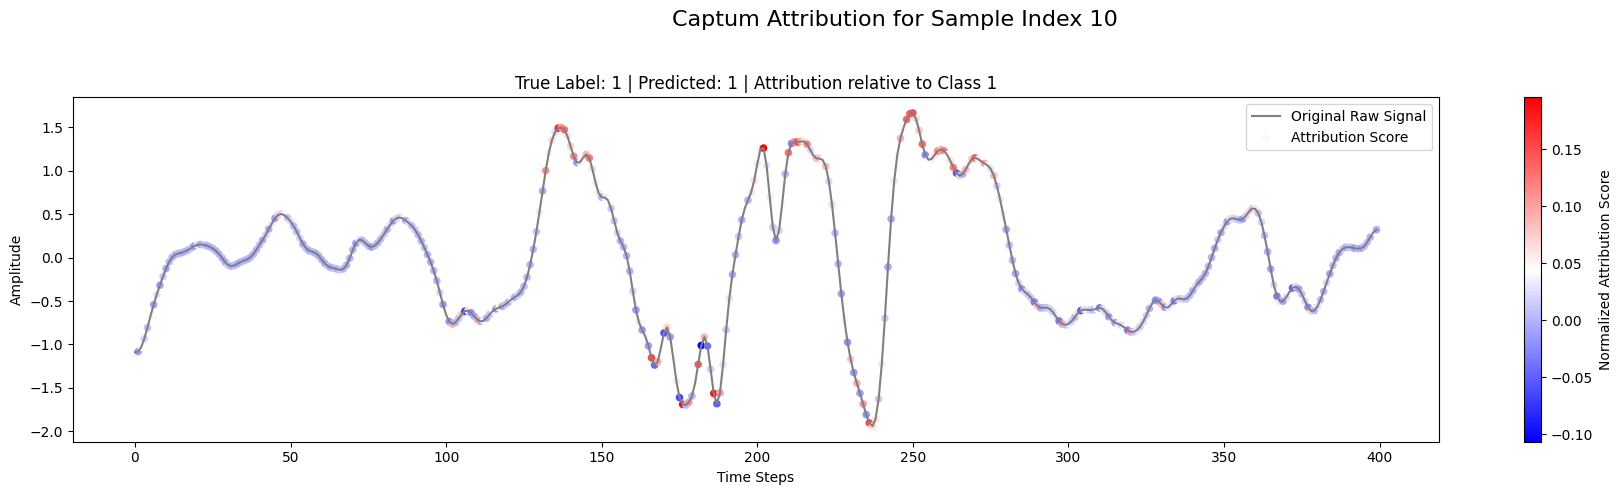


--- Analyzing Sample #3 (Index: 20) ---
True Label: 0 | Model Prediction: 1


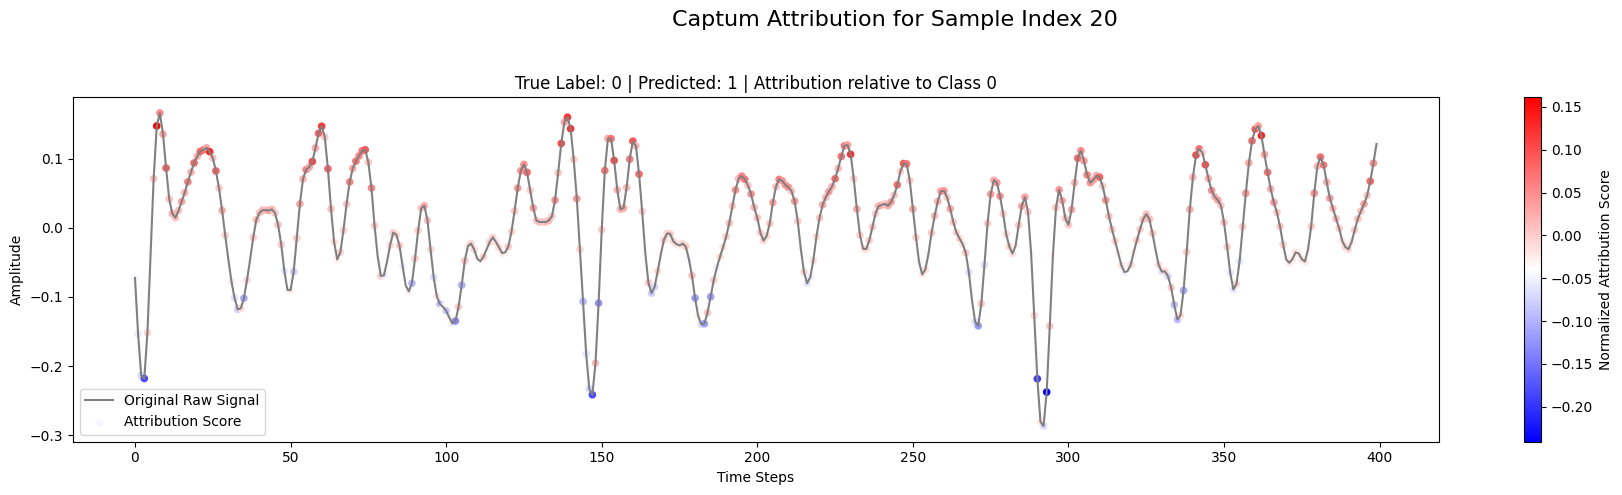


--- Analyzing Sample #4 (Index: 30) ---
True Label: 0 | Model Prediction: 1


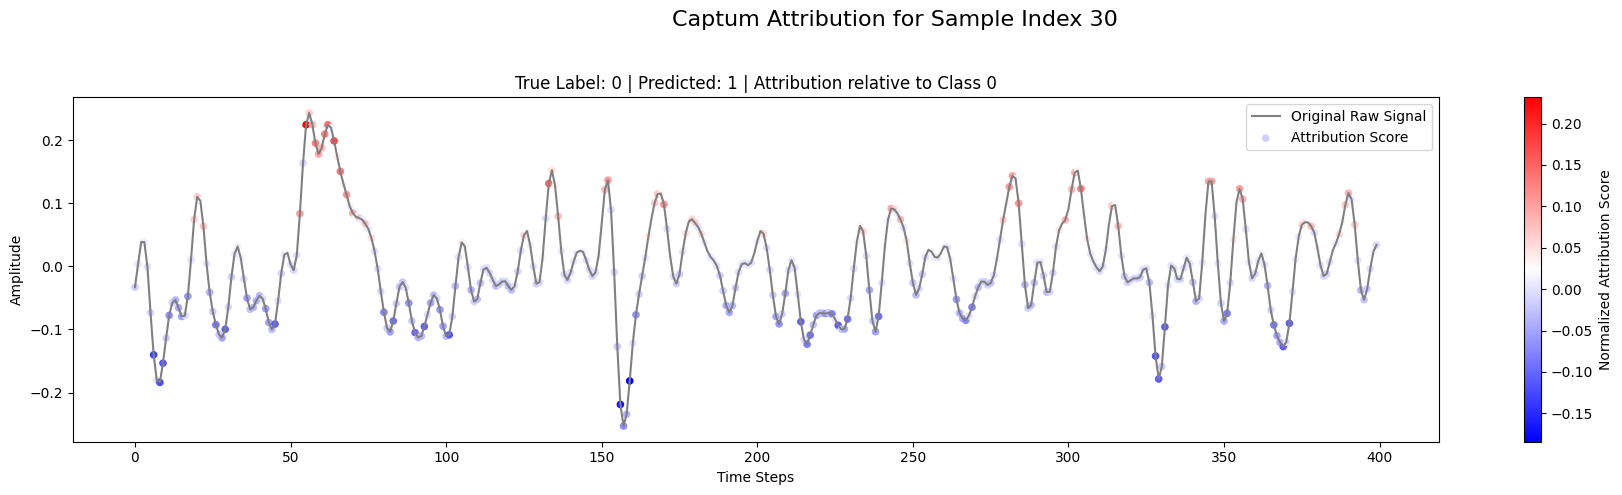

In [9]:
# ====================================================================
# BLOCK 2: CAPTUM INTERPRETABILITY ANALYSIS FOR 4 SAMPLES (Corrected)
# ====================================================================
try:
    from captum.attr import IntegratedGradients

    # --- Step 1: Define the Wrapper Function ---
    def model_wrapper(raw_input_3d):
        """
        Wrapper for the model's forward pass. Captum will pass the correct 3D tensor.
        We create dummy 3D tensors for the other branches.
        """
        # raw_input_3d will have shape [1, 1, 400]
        dummy_fft = torch.zeros_like(raw_input_3d)
        dummy_wavelet = torch.zeros(raw_input_3d.size(0), 30, 400).to(raw_input_3d.device)
        
        main_output, _ = model([raw_input_3d, dummy_fft, dummy_wavelet], active_branch_indices=[0])
        return main_output

    # --- Step 2: Loop Through and Analyze 4 Samples ---
    sample_indices_to_analyze = [0, 10, 20, 30]
    print(f"\n--- Starting Captum Analysis for {len(sample_indices_to_analyze)} Samples ---")

    for i, sample_idx in enumerate(sample_indices_to_analyze):
        print(f"\n--- Analyzing Sample #{i+1} (Index: {sample_idx}) ---")
        
        _, raw_sample, fft_sample, wavelet_sample, label_sample = test_dataset[sample_idx]

        # --- THE FIX ---
        # KEEP the 3D shape [1, 1, 400]. DO NOT squeeze the channel dimension.
        input_tensor_3d = raw_sample.to(device)
        
        target_class = int(label_sample.item())
        
        # Get the model's prediction using the correct 3D tensor
        model.eval()
        with torch.no_grad():
            output, _ = model([input_tensor_3d, fft_sample.to(device), wavelet_sample.to(device)], active_branch_indices=[0])
            prediction = torch.argmax(output, dim=1).item()

        print(f"True Label: {target_class} | Model Prediction: {prediction}")

        # Run Integrated Gradients with the correct 3D input tensor
        ig = IntegratedGradients(model_wrapper)
        baseline = torch.zeros_like(input_tensor_3d)
        attributions, delta = ig.attribute(input_tensor_3d, baselines=baseline, target=target_class, return_convergence_delta=True)

        # --- Step 3: Visualization ---
        # Squeeze all dimensions except the last one for plotting
        attribution_scores_1d = attributions.squeeze().cpu().detach().numpy()
        input_signal_1d = input_tensor_3d.squeeze().cpu().detach().numpy()
            
        # Normalize attribution scores
        norm_val = np.linalg.norm(attribution_scores_1d)
        if norm_val > 0:
            norm_attr = attribution_scores_1d / norm_val
        else:
            norm_attr = np.zeros_like(attribution_scores_1d)
        
        # Create the plot
        fig, ax = plt.subplots(1, 1, figsize=(18, 5))
        fig.suptitle(f'Captum Attribution for Sample Index {sample_idx}', fontsize=16)
        
        time_steps = np.arange(input_signal_1d.shape[0])
        
        ax.plot(time_steps, input_signal_1d, color='gray', label='Original Raw Signal')
        scatter = ax.scatter(time_steps, input_signal_1d, c=norm_attr, cmap='bwr', s=20, label='Attribution Score')
        
        ax.set_title(f"True Label: {target_class} | Predicted: {prediction} | Attribution relative to Class {target_class}")
        ax.set_ylabel('Amplitude')
        ax.set_xlabel('Time Steps')
        ax.legend()
        
        fig.colorbar(scatter, ax=ax, orientation='vertical', label='Normalized Attribution Score')
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

except NameError as e:
     print(f"\nSkipping Captum analysis because a required variable was not found: {e}")
except Exception as e:
    print(f"\nAn error occurred during Captum analysis: {e}")